# 07 · Pooled, location-agnostic PLSR

One model maps vibration -> track quality index, with **no location feature**,
so new/relocated sensors are not out-of-distribution.

- **Features**: `X = sqrt(PSD) / speed` (set in `cfg.feature_sqrt`,
  `cfg.feature_speed_norm_power`). Applied at model time from the raw-PSD store,
  so tuning it needs no re-extraction.
- **Generalization** is measured by **leave-one-location-out** (train on other
  locations, predict the held-out one).
- **Per-location error** is reported for **monitoring only** — never a feature.


In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
from intelliswitch import Config, paths

# --- paths -----------------------------------------------------------------
# The project data lake (medallion tiers) is resolved by intelliswitch.paths, so
# it works regardless of the notebook's working dir and is overridable via the
# INTELLISWITCH_DATA_DIR / INTELLISWITCH_MODELS_DIR env vars.
RAW_CACHE = paths.RAW_CACHE       # data/interim/raw_cache  (decoded .npz, stage 1)
STORE     = paths.FEATURE_STORE   # data/processed/feature_store
MODELS    = paths.MODELS          # data/models
paths.ensure()                    # create the lake dirs if missing

# Raw source recordings (~7,800 logs) are large and live on the external drive;
# point DATA_ROOT at them, or symlink/copy the source into paths.RAW.
DATA_ROOT = Path(r"/Volumes/Seagate Expansion Drive/Mohammad/M Drive DTU/MATLAB Scripts/IntelliswitchScripts")
W10   = DATA_ROOT / "W10v140"       # vibration .log
BLADE = DATA_ROOT / "Bladenr8252"   # geometry .csv

cfg = Config()
print('features: sqrt(PSD)=%s  / speed**%.1f' % (cfg.feature_sqrt, cfg.feature_speed_norm_power))

features: sqrt(PSD)=True  / speed**1.0


## Load cached features, select trains, attach labels
`select_trains` applies the *selection* choices (speed > `min_speed_kmh`,
train type) — separate from extraction quality. Speed is no longer a QC
reject, so tune `cfg.min_speed_kmh` here without re-extracting.


In [2]:
from intelliswitch.pipeline import load_feature_store, select_trains
from intelliswitch.geometry import align_campaigns, build_deg_model
from intelliswitch.geometry.deg_model import attach_labels

feat = select_trains(load_feature_store(STORE), cfg)   # speed/type selection
deg = build_deg_model(align_campaigns(BLADE, cfg), cfg)
data = attach_labels(feat, deg, cfg).dropna(subset=['y'])
print('rows after selection + labels:', len(data))
data.groupby('sensor').size()


rows after selection + labels: 122


sensor
A1     18
A11    74
A2     30
dtype: int64

## Train the single pooled model


In [3]:
from intelliswitch.model import fit_pooled, evaluate, leave_one_location_out
model = fit_pooled(data, cfg)              # backend = cfg.model_kind ('plsr')
print(f'pooled {model.kind}: {model.info}  n_train={model.n_train}  train_R2={model.train_r2:.3f}')


pooled plsr: {'backend': 'plsr', 'n_components': 5}  n_train=10  train_R2=0.999


## Overall performance + per-location monitoring
Same model everywhere; the per-location rows are a monitoring view, not
separate models.


In [4]:
ev = evaluate(model, data, cfg)
o = ev['overall']
print(f"OVERALL  test_pts={o['n_testpoints']}  MAPE={o['mape']:.1f}%  corr={o['corr']:.2f}")
rows = [dict(sensor=n, test_pts=e['n_testpoints'], MAPE=round(e['mape'],1), corr=round(e['corr'],2))
        for n, e in ev['per_location'].items()]
pd.DataFrame(rows)


OVERALL  test_pts=1  MAPE=4.2%  corr=nan


,sensor,test_pts,MAPE,corr
0,A1,1,7.1,NaN
1,A2,1,53.3,NaN
2,A11,1,7.8,NaN


## Generalization: leave-one-location-out
Train on the other locations, predict the held-out one. If these scores are
close to the monitoring scores above, the features are location-invariant
enough to trust on new locations.


In [5]:
rows = []
for name, e in leave_one_location_out(data, cfg).items():
    if 'mape' in e:
        rows.append(dict(held_out=name, test_pts=e['n_testpoints'],
                         MAPE=round(e['mape'],1), corr=round(e['corr'],2)))
    else:
        rows.append(dict(held_out=name, error=e.get('error')))
pd.DataFrame(rows)


,held_out,test_pts,MAPE,corr,error
0,A1,1.0,10.5,NaN,NaN
1,A2,1.0,92.2,NaN,NaN
2,A11,NaN,NaN,NaN,too few training rows (2) for 'LOLO-not-A11'


## Plot: pooled prediction vs reference, per location (monitoring)


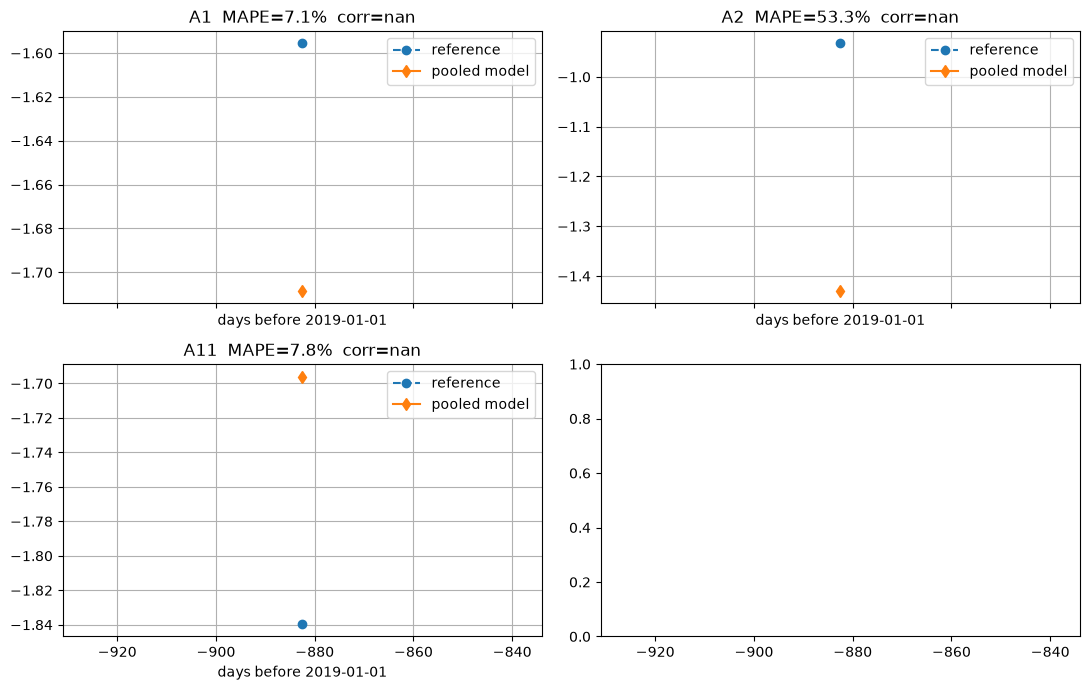

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (name, e) in zip(axes.ravel(), ev['per_location'].items()):
    ax.plot(e['mid_days'], e['ref'],  '--o', label='reference')
    ax.plot(e['mid_days'], e['pred'], '-d',  label='pooled model')
    ax.set_title(f"{name}  MAPE={e['mape']:.1f}%  corr={e['corr']:.2f}")
    ax.set_xlabel('days before 2019-01-01'); ax.grid(True); ax.legend()
plt.tight_layout(); plt.show()


### Notes
- Tune `cfg.feature_speed_norm_power` (e.g. 0, 1, 2) and `cfg.feature_sqrt`
  here — no re-extraction needed.
- High MAPE near zero-valued references is a metric artifact; correlation is
  the stabler indicator at the test points.
